EPC2037 DATASHEET CARD
------------------------------------------------------------
V_DS_max = 100.0 V, I_D_max = 1.70 A
R_on,typ = 400 mΩ, R_on,max = 550 mΩ
Q_G = 115 pC, Q_GS = 32 pC, Q_GD = 25 pC, R_G = 0.5 Ω
C_ISS = 14.0 pF, C_RSS = 0.10 pF
C_OSS(50V) = 6.5 pF, C_OSS(ER) = 9.5 pF, C_OSS(TR) = 12.0 pF
Q_OSS(50V) = 600 pC (max 900 pC)
C_OSS(50V) max = 10.0 pF
E_OSS(ER, 50V) = 11.8750 nJ
P_gate = 8.050 mW

ANALYTICAL CLASS-E DESIGN
------------------------------------------------------------
KR = 0.576801, KC = 0.183601, KL = 1.152494, phi = 147.518°
Ropt = 8.2229 Ω, Csh = 253.830 pF
L1 = 107.735 nH, L2 = 280.439 nH, C2 = 460.835 pF
Cext (from const 12 pF assumption) = 241.830 pF
IDC Sokal = 340.206 mA, IR Sokal = 633.497 mA, P_gate = 8.050 mW

TEMPERATURE MODEL (Fig 8)
------------------------------------------------------------
RON typical @ 75°C = 0.5200 Ω, RON maximum @ 75°C = 0.7150 Ω
Model equiv C_ER = 9.500 pF

COSS MODEL SUMMARY (Raw Kennlinie)
--------------------------------

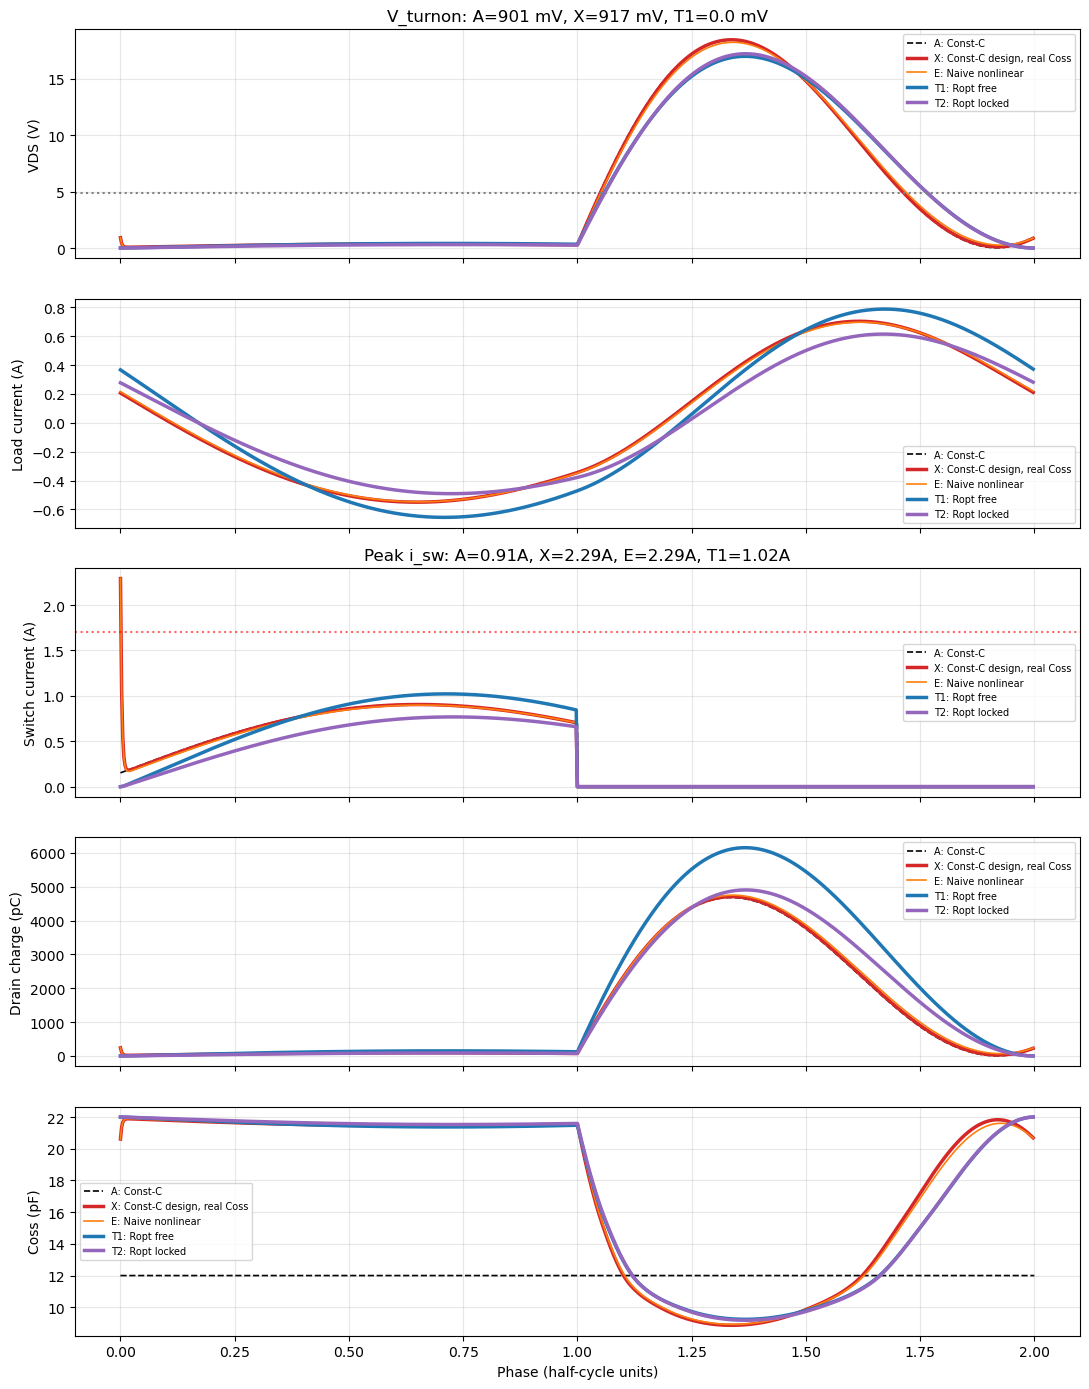

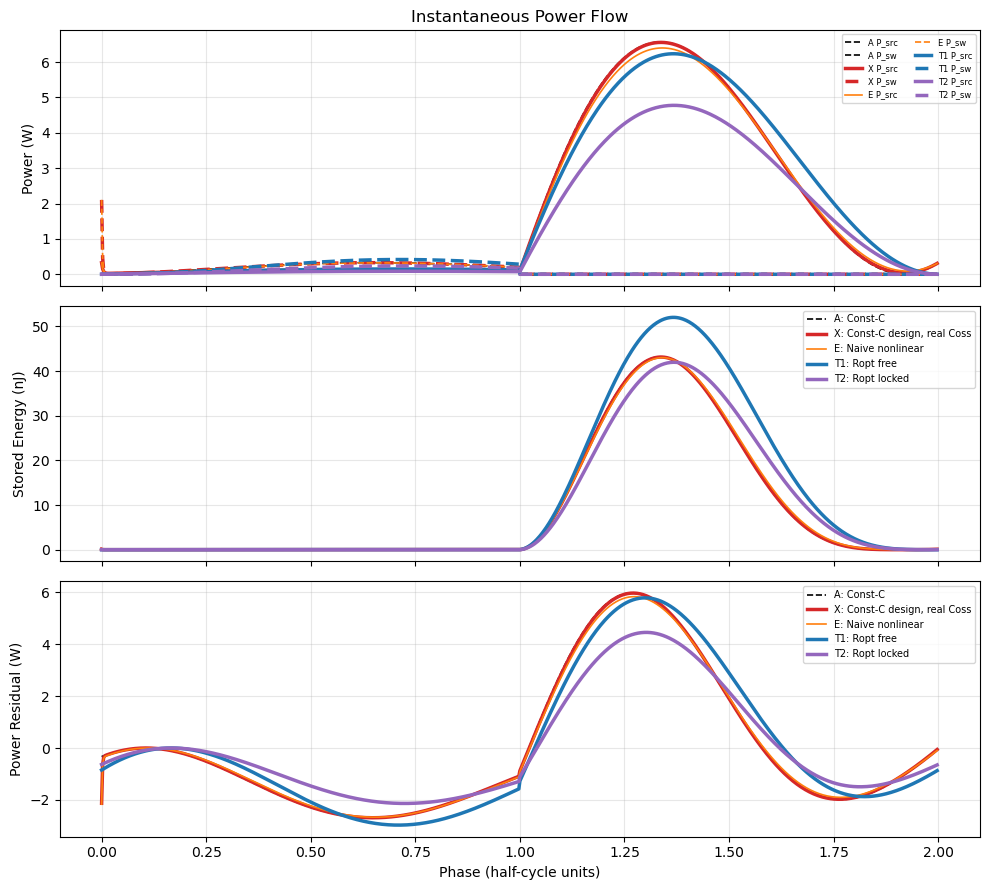

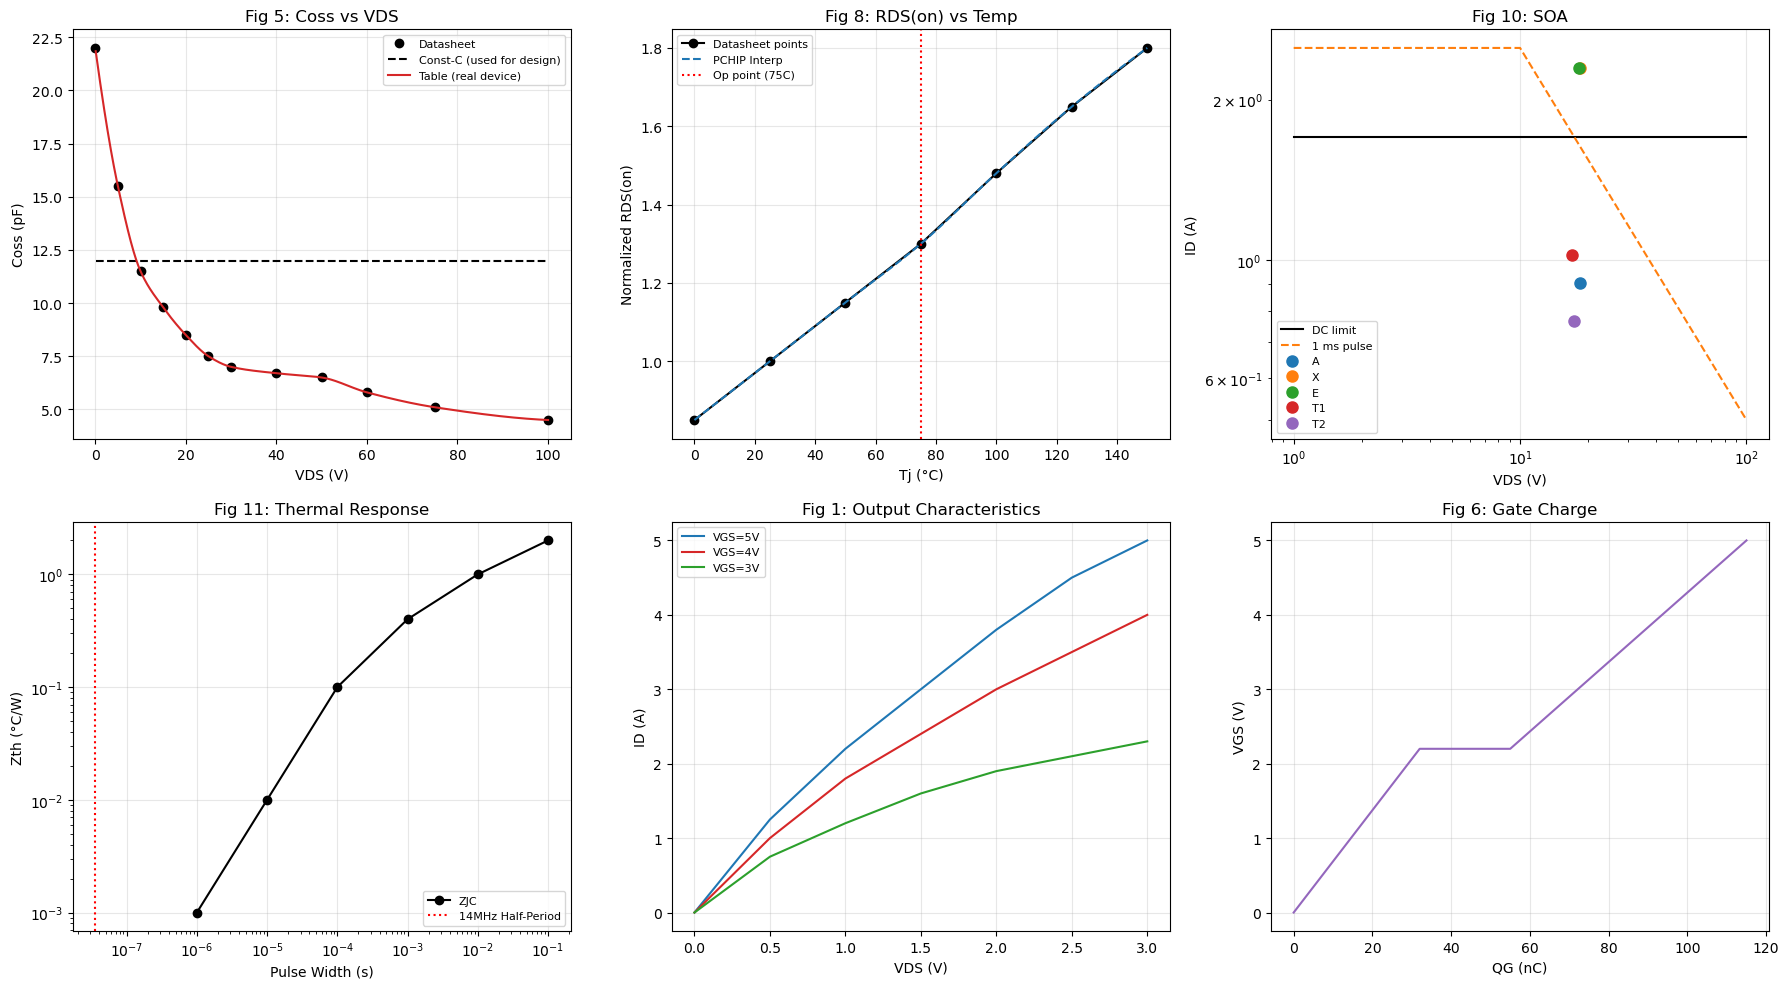

In [1]:
# =============================================================================
# CONSOLIDATED EPC2037 GaN CLASS-E AMPLIFIER NOTEBOOK
# Corrected: Raw digitized Kennlinien, no artificial calibration
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import brentq, minimize
from scipy.interpolate import PchipInterpolator
import pandas as pd
import warnings
import time

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# =============================================================================
# Layer 1 — Datasheet Card & Analytical Design
# =============================================================================
VDD, POUT_TARGET, F0 = 4.85, 1.65, 14.0e6
W0, T, TH = 2*np.pi*F0, 1/F0, 1/(2*F0)
VDS_MAX, ID_MAX = 100.0, 1.7
RON_25, RON_MAX_25 = 0.400, 0.550
QG, VG = 115e-12, 5.0
PGATE = QG*VG*F0
COSS_50, QOSS_50, COSS_TR = 6.5e-12, 600e-12, 12e-12
COSS_ER, COSS_50_MAX = 9.5e-12, 10e-12
QOSS_50_MAX = 900e-12
EOSS_ER_50 = 0.5*COSS_ER*50**2
QGS, QGD, RG = 32e-12, 25e-12, 0.5
CISS, CRSS = 14e-12, 0.1e-12

print("EPC2037 DATASHEET CARD")
print("-"*60)
print(f"V_DS_max = {VDS_MAX:.1f} V, I_D_max = {ID_MAX:.2f} A")
print(f"R_on,typ = {RON_25*1e3:.0f} mΩ, R_on,max = {RON_MAX_25*1e3:.0f} mΩ")
print(f"Q_G = {QG*1e12:.0f} pC, Q_GS = {QGS*1e12:.0f} pC, Q_GD = {QGD*1e12:.0f} pC, R_G = {RG} Ω")
print(f"C_ISS = {CISS*1e12:.1f} pF, C_RSS = {CRSS*1e12:.2f} pF")
print(f"C_OSS(50V) = {COSS_50*1e12:.1f} pF, C_OSS(ER) = {COSS_ER*1e12:.1f} pF, C_OSS(TR) = {COSS_TR*1e12:.1f} pF")
print(f"Q_OSS(50V) = {QOSS_50*1e12:.0f} pC (max {QOSS_50_MAX*1e12:.0f} pC)")
print(f"C_OSS(50V) max = {COSS_50_MAX*1e12:.1f} pF")
print(f"E_OSS(ER, 50V) = {EOSS_ER_50*1e9:.4f} nJ")
print(f"P_gate = {PGATE*1e3:.3f} mW")

# Analytical Design
a = 2/np.sqrt(np.pi**2 + 4)
phi = np.pi - np.arctan(2/np.pi)
KR, KC = 2*a**2, 2*a**2/np.pi
Ropt_ana = KR*VDD**2/POUT_TARGET
Csh_ideal = KC/(W0*Ropt_ana)

IR_norm = np.sqrt(2/KR)
IDC_norm = a*IR_norm
C_norm = KC/KR
th = np.linspace(0, 2*np.pi, 200001)
vd_norm = np.zeros_like(th)
off = th >= np.pi
vd_norm[off] = (IDC_norm*(th[off]-np.pi) + IR_norm*(np.cos(th[off]+phi)-np.cos(np.pi+phi)))/C_norm
V1 = np.trapezoid(vd_norm*np.exp(-1j*th), th)/np.pi
I1 = IR_norm*np.exp(1j*(phi-np.pi/2))
KL = (V1/I1).imag/(V1/I1).real
L1_ana = KL*Ropt_ana/W0
L2_ana = 3.0*Ropt_ana/W0
C2_ana = 1/(W0**2*L2_ana)
LT_ana = L1_ana + L2_ana
IDC_sk = POUT_TARGET/VDD
IR_sk = np.sqrt(2*POUT_TARGET/Ropt_ana)
Cext_const = Csh_ideal - COSS_TR

print("\nANALYTICAL CLASS-E DESIGN")
print("-"*60)
print(f"KR = {KR:.6f}, KC = {KC:.6f}, KL = {KL:.6f}, phi = {np.degrees(phi):.3f}°")
print(f"Ropt = {Ropt_ana:.4f} Ω, Csh = {Csh_ideal*1e12:.3f} pF")
print(f"L1 = {L1_ana*1e9:.3f} nH, L2 = {L2_ana*1e9:.3f} nH, C2 = {C2_ana*1e12:.3f} pF")
print(f"Cext (from const 12 pF assumption) = {Cext_const*1e12:.3f} pF")
print(f"IDC Sokal = {IDC_sk*1e3:.3f} mA, IR Sokal = {IR_sk*1e3:.3f} mA, P_gate = {PGATE*1e3:.3f} mW")


# =============================================================================
# Layer 2 — Corrected Temperature & Coss Models (No Calibration)
# =============================================================================
DS_FIG8_TJ = np.array([0, 25, 50, 75, 100, 125, 150.])
DS_FIG8_RDS_NORM = np.array([0.85, 1.00, 1.15, 1.30, 1.48, 1.65, 1.80])
_rds_curve = PchipInterpolator(DS_FIG8_TJ, DS_FIG8_RDS_NORM, extrapolate=False)
def temperature_factor(Tj): return float(_rds_curve(Tj))
RON_TYP_75 = RON_25 * temperature_factor(75.0)
RON_MAX_75 = RON_MAX_25 * temperature_factor(75.0)

print("\nTEMPERATURE MODEL (Fig 8)")
print("-"*60)
print(f"RON typical @ 75°C = {RON_TYP_75:.4f} Ω, RON maximum @ 75°C = {RON_MAX_75:.4f} Ω")
print(f"Model equiv C_ER = {2*EOSS_ER_50/50**2*1e12:.3f} pF")

# Fig 5: RAW Digitized Coss (NO calibration)
DS_FIG5_VDS = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100.])
DS_FIG5_COSS = 1e-12*np.array([22.0, 15.5, 11.5, 9.8, 8.5, 7.5, 7.0, 6.7, 6.5, 5.8, 5.1, 4.5])
DS_FIG5_CRSS = 1e-12*np.array([2.0, 0.7, 0.2, 0.15, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.08, 0.05])
_coss_dig = PchipInterpolator(DS_FIG5_VDS, DS_FIG5_COSS, extrapolate=False)

V_GRID = np.linspace(0, 150, 150001)
C_GRID = _coss_dig(np.clip(V_GRID, 0, 100))
Q_GRID = cumulative_trapezoid(C_GRID, V_GRID, initial=0)
E_GRID = cumulative_trapezoid(V_GRID*C_GRID, V_GRID, initial=0)

Q_RAW_50 = Q_GRID[np.argmin(np.abs(V_GRID-50))]

_coss_tab, _qoss_tab, _eoss_tab = PchipInterpolator(V_GRID, C_GRID), PchipInterpolator(V_GRID, Q_GRID), PchipInterpolator(V_GRID, E_GRID)

def coss_const(v): return np.full_like(np.asarray(v, float), COSS_TR)
def qoss_const(v): return COSS_TR*np.abs(np.asarray(v, float))
def eoss_const(v): return 0.5*COSS_TR*np.asarray(v, float)**2

def coss_tab(v): return _coss_tab(np.clip(np.abs(v), 0, 150))
def qoss_tab(v): return np.sign(v)*_qoss_tab(np.abs(v))
def eoss_tab(v): return _eoss_tab(np.abs(v))

print("\nCOSS MODEL SUMMARY (Raw Kennlinie)")
print("-"*60)
print(f"Integrated Qoss(50 V) from curve = {Q_RAW_50*1e12:.2f} pC")
print(f"Datasheet nominal Qoss(50 V) = {QOSS_50*1e12:.2f} pC")
print(f"Coss at 50 V (from curve) = {coss_tab(50)*1e12:.2f} pF")
print(f"Model Eoss(50 V) = {eoss_tab(50)*1e9:.4f} nJ")


# =============================================================================
# Layer 3 — Simulation Engine
# =============================================================================
class DeviceModel:
    def __init__(self, coss_f, qoss_f, eoss_f, Cext, Ron, kind="nonlin"):
        self.coss_f, self.qoss_f, self.eoss_f = coss_f, qoss_f, eoss_f
        self.Cext, self.Ron, self.kind = float(Cext), float(Ron), kind
        self._vg = np.linspace(0, 150, 150001)
        self._qg = self.Cext*self._vg + np.asarray(self.qoss_f(self._vg), float)
    def v_from_q(self, q):
        q = float(q)
        if abs(q) < 1e-30: return 0.0
        return np.sign(q)*float(np.interp(abs(q), self._qg, self._vg))
    def e_total(self, v): return 0.5*self.Cext*np.asarray(v, float)**2 + np.asarray(self.eoss_f(v), float)

def cycle_const(IDC, Ron, LT_val, C2_val, Ropt_val, Csh_val, warmup=500, samples=1000):
    def f_on(t, y):
        iL, vC2 = y
        return [(Ron*(IDC-iL) - vC2 - Ropt_val*iL)/LT_val, iL/C2_val]
    def f_off(t, y):
        vD, iL, vC2 = y
        return [(IDC-iL)/Csh_val, (vD-vC2-Ropt_val*iL)/LT_val, iL/C2_val]
    iL, vC2 = 0.0, 0.0
    for _ in range(warmup):
        s1 = solve_ivp(f_on, [0, TH], [iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13, max_step=TH/20)
        iL, vC2 = s1.y[0, -1], s1.y[1, -1]
        s2 = solve_ivp(f_off, [0, TH], [Ron*(IDC-iL), iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True, max_step=TH/20)
        iL, vC2 = s2.y[1, -1], s2.y[2, -1]
    s1 = solve_ivp(f_on, [0, TH], [iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True, max_step=TH/20)
    iL_on, vC2_on = s1.y[0, -1], s1.y[1, -1]
    s2 = solve_ivp(f_off, [0, TH], [Ron*(IDC-iL_on), iL_on, vC2_on], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True, max_step=TH/20)
    t_on, t_off = np.linspace(0, TH, samples+1), np.linspace(0, TH, samples+1)
    y_on, y_off = s1.sol(t_on), s2.sol(t_off)
    t = np.concatenate([t_on, TH+t_off[1:]])
    vD = np.concatenate([Ron*(IDC-y_on[0]) if Ron > 0 else np.zeros_like(t_on), y_off[0][1:]])
    iL_f = np.concatenate([y_on[0], y_off[1][1:]])
    i_sw = np.concatenate([IDC-y_on[0], np.zeros_like(y_off[1][1:])])
    q = Csh_val * vD
    coss = np.full_like(vD, COSS_TR)
    return {"t": t, "v_D": vD, "i_L": iL_f, "i_sw": i_sw, "q": q, "Coss": coss, "v_avg": np.trapezoid(vD, t)/T,
            "v_peak": vD.max(), "v_min": vD.min(), "v_turnon": float(s2.sol(TH)[0]),
            "i_turnon": float(s2.sol(TH)[1])}

def cycle_nonlin(IDC, dev, LT_val, C2_val, Ropt_val, warmup=100, samples=400):
    def f_on(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL-vD/dev.Ron, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    def f_off(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    y = np.zeros(3)
    for _ in range(warmup):
        s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12, max_step=TH/20)
        s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12, max_step=TH/20)
        y = s2.y[:, -1]
    s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True, max_step=TH/20)
    s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True, max_step=TH/20)
    t1, t2 = np.linspace(0, TH, samples, endpoint=False), np.linspace(0, TH, samples, endpoint=False)
    y1, y2 = s1.sol(t1), s2.sol(t2)
    q = np.r_[y1[0], y2[0]]; iL = np.r_[y1[1], y2[1]]
    t = np.r_[t1, TH+t2]
    vD = np.array([dev.v_from_q(z) for z in q])
    iSW = np.r_[vD[:samples]/dev.Ron, np.zeros(samples)]
    coss_wave = np.array([dev.coss_f(v) for v in vD])
    return {"t": t, "q": q, "v_D": vD, "i_L": iL, "i_sw": iSW, "Coss": coss_wave, "v_avg": np.trapezoid(vD, t)/T,
            "v_peak": np.max(vD), "v_min": np.min(vD), "v_turnon": float(dev.v_from_q(s2.y[0, -1])),
            "i_turnon": float(s2.y[1, -1])}

def solve_const(Ron, LT_val, C2_val, Ropt_val, Csh_val):
    def resid(I): return cycle_const(I, Ron, LT_val, C2_val, Ropt_val, Csh_val, warmup=200)["v_avg"] - VDD
    I = brentq(resid, 0.7*IDC_sk, 1.3*IDC_sk, xtol=1e-7)
    return cycle_const(I, Ron, LT_val, C2_val, Ropt_val, Csh_val, warmup=500), I

def solve_nonlin(dev, LT_val, C2_val, Ropt_val, warmup=50, samples=200):
    def resid(I): return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup, samples=samples)["v_avg"] - VDD
    I = brentq(resid, 0.05*POUT_TARGET/VDD, 3.0*POUT_TARGET/VDD, xtol=1e-8)
    return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup*2, samples=samples*2), I

def run_point(kind, Ron, L1_val, L2_val, C2_val, Ropt_val, Cext, label=""):
    LT_val = L1_val + L2_val
    if kind == "const":
        dev = DeviceModel(coss_const, qoss_const, eoss_const, Cext, Ron, kind="const")
        h, I = solve_const(Ron, LT_val, C2_val, Ropt_val, Cext + COSS_TR)
        P_load = np.trapezoid(Ropt_val*h["i_L"]**2, h["t"])/T
        P_Ron = Ron*np.trapezoid(h["i_sw"]**2, h["t"])/T
        P_ZVS = 0.5*(Cext + COSS_TR)*h["v_turnon"]**2*F0
        E_turn = 0.5*(Cext + COSS_TR)*h["v_turnon"]**2
        Ecap = 0.5*(Cext + COSS_TR)*h["v_D"]**2
    else:
        dev = DeviceModel(coss_tab, qoss_tab, eoss_tab, Cext, Ron, kind="nonlin")
        h, I = solve_nonlin(dev, LT_val, C2_val, Ropt_val)
        P_load = np.trapezoid(Ropt_val*h["i_L"]**2, h["t"])/T
        P_Ron = Ron*np.trapezoid(h["i_sw"]**2, h["t"])/T
        P_ZVS = 0.0
        E_turn = float(dev.e_total(h["v_turnon"]))
        Ecap = dev.e_total(h["v_D"])
    return {
        "h": h, "I": I, "P_load": P_load, "P_Ron": P_Ron, "P_ZVS": P_ZVS,
        "E_turn": E_turn, "E_cap_avg": np.trapezoid(Ecap, h["t"])/T, "E_cap_delta": Ecap[-1]-Ecap[0],
        "eta_system": P_load/(VDD*I + PGATE), "dev": dev,
        "L1_used": L1_val, "L2_used": L2_val, "C2_used": C2_val,
        "Ropt_used": Ropt_val, "Cext_used": Cext, "label": label,
    }

print("\nRunning baseline cases A, X, E...")
res = {}
res["A"] = run_point("const", RON_25, L1_ana, L2_ana, C2_ana, Ropt_ana, Cext_const, "A: Const-C")
res["X"] = run_point("tab",   RON_25, L1_ana, L2_ana, C2_ana, Ropt_ana, Cext_const, "X: Const-C design, real Coss")
res["E"] = run_point("tab",   RON_25, L1_ana, L2_ana, C2_ana, Ropt_ana, Csh_ideal - COSS_50, "E: Naive nonlinear")

for k in ["A", "X", "E"]:
    h = res[k]["h"]; p = res[k]
    print(f"\n--- Case {k} ({p['label']}) ---")
    print(f"  I_DC = {p['I']*1e3:.4f} mA | Avg drain V = {h['v_avg']:.5f} V")
    print(f"  V_pk = {h['v_peak']:.4f} V | V_min = {h['v_min']:.4f} V | V_turnon = {h['v_turnon']*1e3:.2f} mV")
    print(f"  i_turnon = {h['i_turnon']:.4f} A | i_sw_pk = {np.max(h['i_sw']):.4f} A")
    print(f"  P_load = {p['P_load']*1e3:.4f} mW | P_Ron = {p['P_Ron']*1e3:.4f} mW | eta_sys = {p['eta_system']*100:.2f}%")
    print(f"  E_cap_avg = {p['E_cap_avg']*1e9:.5f} nJ | E_cap_delta = {p['E_cap_delta']*1e9:+.3e} nJ")


# =============================================================================
# Layer 4 — Verbose Optimization (Heartbeat dots only)
# =============================================================================
global eval_count
eval_count = 0

def make_eval(fixed_ropt):
    global eval_count
    cache = {}
    def ev(x):
        global eval_count
        key = tuple(np.round(x, 5))
        if key in cache: return cache[key]
        eval_count += 1
        if eval_count % 10 == 0:
            print(".", end="", flush=True)
        if fixed_ropt is None:
            Cext, L1v, L2v, C2v, Roptv = x[0]*1e-12, x[1]*1e-9, x[2]*1e-9, x[3]*1e-12, x[4]
        else:
            Cext, L1v, L2v, C2v = x[0]*1e-12, x[1]*1e-9, x[2]*1e-9, x[3]*1e-12
            Roptv = fixed_ropt
        LTv = L1v + L2v
        dev = DeviceModel(coss_tab, qoss_tab, eoss_tab, Cext, RON_25, "nonlin")
        try:
            h, I = solve_nonlin(dev, LTv, C2v, Roptv, warmup=20, samples=100)
            P_load = np.trapezoid(Roptv*h["i_L"]**2, h["t"])/T
            eta = P_load/(VDD*I + PGATE)
            Csh_tot = Cext + dev.coss_f(h["v_turnon"])
            dVdt = (I - h["i_turnon"]) / Csh_tot
            r = (h["v_turnon"], dVdt, P_load, eta, np.max(h["i_sw"]))
        except Exception:
            r = (10.0, 10.0, 0.0, 0.0, 10.0)
        cache[key] = r
        return r
    return ev

# --- T1: Ropt Free, P=1.65W ---
print("\n" + "="*80)
print("T1: Ropt FREE, P = 1.65 W, maximize efficiency")
print("="*80)
print("Starting SLSQP... (dots = 10 function evaluations)")
eval_count = 0
ev1 = make_eval(None)
def obj1(x): return -ev1(x)[3]
cons1 = [
    {'type': 'eq', 'fun': lambda x: ev1(x)[0]},
    {'type': 'eq', 'fun': lambda x: ev1(x)[1]*1e-8},
    {'type': 'eq', 'fun': lambda x: ev1(x)[2] - POUT_TARGET},
]
x0_5 = [247.33, 107.73, 280.44, 460.83, Ropt_ana]
bnd_5 = [(100, 500), (50, 250), (150, 450), (200, 900), (3.0, 20.0)]
t0_T1 = time.time()
res1 = minimize(obj1, x0_5, method='SLSQP', bounds=bnd_5, constraints=cons1,
                options={'maxiter': 100, 'eps': 1e-4})
print(f"\nT1 finished in {time.time()-t0_T1:.1f}s. Status: {res1.message}")
Cext_1, L1_1, L2_1, C2_1, Ropt_1 = res1.x[0]*1e-12, res1.x[1]*1e-9, res1.x[2]*1e-9, res1.x[3]*1e-12, res1.x[4]
res["T1"] = run_point("tab", RON_25, L1_1, L2_1, C2_1, Ropt_1, Cext_1, "T1: Ropt free, P=1.65W")

# --- T2: Ropt Locked, P Free ---
print("\n" + "="*80)
print("T2: Ropt LOCKED at 8.223, P FREE, maximize efficiency")
print("="*80)
print("Starting SLSQP... (dots = 10 function evaluations)")
eval_count = 0
ev2 = make_eval(Ropt_ana)
def obj2(x): return -ev2(x)[3]
cons2 = [
    {'type': 'eq', 'fun': lambda x: ev2(x)[0]},
    {'type': 'eq', 'fun': lambda x: ev2(x)[1]*1e-8},
]
x0_4 = [247.33, 107.73, 280.44, 460.83]
bnd_4 = [(100, 500), (50, 250), (150, 450), (200, 900)]
t0_T2 = time.time()
res2 = minimize(obj2, x0_4, method='SLSQP', bounds=bnd_4, constraints=cons2,
                options={'maxiter': 100, 'eps': 1e-4})
print(f"\nT2 finished in {time.time()-t0_T2:.1f}s. Status: {res2.message}")
Cext_2, L1_2, L2_2, C2_2 = res2.x[0]*1e-12, res2.x[1]*1e-9, res2.x[2]*1e-9, res2.x[3]*1e-12
res["T2"] = run_point("tab", RON_25, L1_2, L2_2, C2_2, Ropt_ana, Cext_2, "T2: Ropt locked, P free")


# =============================================================================
# Layer 5 — Diagnostics, Tables, and Deltas
# =============================================================================
summary = pd.DataFrame([{
    "Tag": k,
    "L1 (nH)": res[k]["L1_used"]*1e9,
    "L2 (nH)": res[k]["L2_used"]*1e9,
    "C2 (pF)": res[k]["C2_used"]*1e12,
    "Cext (pF)": res[k]["Cext_used"]*1e12,
    "Ropt (Ω)": res[k]["Ropt_used"],
    "V_on (V)": res[k]["h"]["v_turnon"],
    "i_sw_pk (A)": np.max(res[k]["h"]["i_sw"]),
    "P_load (mW)": res[k]["P_load"]*1e3,
    "P_Ron (mW)": res[k]["P_Ron"]*1e3,
    "η_sys (%)": res[k]["eta_system"]*100,
} for k in ["A","X","E","T1","T2"]])

print("\n### FULL DIAGNOSTICS TABLE\n")
print(summary.round(3).to_string(index=False))

delta_rows = []
for k in ["T1", "T2"]:
    d = {}
    for fld, used_key, ana_val in [
        ("Cext", "Cext_used", Cext_const), ("L1", "L1_used", L1_ana),
        ("L2", "L2_used", L2_ana), ("C2", "C2_used", C2_ana),
        ("Ropt", "Ropt_used", Ropt_ana),
    ]:
        d[fld] = res[k][used_key] - ana_val
    d["Tag"] = k
    delta_rows.append(d)

delta_df = pd.DataFrame(delta_rows)[["Tag", "Cext", "L1", "L2", "C2", "Ropt"]]
for col, scale in [("Cext", 1e12), ("L1", 1e9), ("L2", 1e9), ("C2", 1e12), ("Ropt", 1)]:
    delta_df[col] = (delta_df[col] * scale).round(2)

print("\n### ABSOLUTE DELTAS FROM ANALYTICAL (T - A)\n")
print(delta_df.to_string(index=False))


# =============================================================================
# Layer 6 — Time-Domain Waveform Overlays (5 subplots)
# =============================================================================
sel = [("A", "A: Const-C", "k--"), ("X", "X: Const-C design, real Coss", "C3-"),
       ("E", "E: Naive nonlinear", "C1-"), ("T1", "T1: Ropt free", "C0-"),
       ("T2", "T2: Ropt locked", "C4-")]
fig, ax = plt.subplots(5, 1, figsize=(11, 14), sharex=True)
for key, lab, col in sel:
    h = res[key]["h"]; ph = h["t"]/TH
    lw = 2.5 if key in ("X", "T1", "T2") else 1.2
    ax[0].plot(ph, h["v_D"], col, lw=lw, label=lab)
    ax[1].plot(ph, h["i_L"], col, lw=lw, label=lab)
    ax[2].plot(ph, h["i_sw"], col, lw=lw, label=lab)
    ax[3].plot(ph, h["q"]*1e12, col, lw=lw, label=lab)
    ax[4].plot(ph, h["Coss"]*1e12, col, lw=lw, label=lab)
ax[0].axhline(VDD, color="gray", ls=":"); ax[0].set_ylabel("VDS (V)")
ax[0].set_title(f"V_turnon: A={res['A']['h']['v_turnon']*1e3:.0f} mV, X={res['X']['h']['v_turnon']*1e3:.0f} mV, T1={res['T1']['h']['v_turnon']*1e3:.1f} mV")
ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)
ax[1].set_ylabel("Load current (A)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
ax[2].axhline(ID_MAX, color="red", ls=":", alpha=0.6)
ax[2].set_ylabel("Switch current (A)"); ax[2].set_title(f"Peak i_sw: A={np.max(res['A']['h']['i_sw']):.2f}A, X={np.max(res['X']['h']['i_sw']):.2f}A, E={np.max(res['E']['h']['i_sw']):.2f}A, T1={np.max(res['T1']['h']['i_sw']):.2f}A")
ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)
ax[3].set_ylabel("Drain charge (pC)"); ax[3].legend(fontsize=7); ax[3].grid(alpha=0.3)
ax[4].set_ylabel("Coss (pF)"); ax[4].set_xlabel("Phase (half-cycle units)"); ax[4].legend(fontsize=7); ax[4].grid(alpha=0.3)
plt.tight_layout(); plt.show()


# =============================================================================
# Layer 7 — Power & Energy Overlays (3 subplots)
# =============================================================================
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for key, lab, col in sel:
    h = res[key]["h"]; ph = h["t"]/TH; dev = res[key]["dev"]; I = res[key]["I"]; Ropt_v = res[key]["Ropt_used"]
    P_src = I*h["v_D"]; P_sw = dev.Ron*h["i_sw"]**2; P_load = Ropt_v*h["i_L"]**2
    E_cap = dev.e_total(h["v_D"]) if dev.kind != "const" else 0.5*(res[key]["Cext_used"]+COSS_TR)*h["v_D"]**2
    lw = 2.5 if key in ("X", "T1", "T2") else 1.2
    ax[0].plot(ph, P_src, col, lw=lw, label=f"{key} P_src")
    ax[0].plot(ph, P_sw, col, lw=lw, ls="--", label=f"{key} P_sw")
    ax[1].plot(ph, E_cap*1e9, col, lw=lw, label=lab)
    ax[2].plot(ph, P_src - P_sw - P_load, col, lw=lw, label=lab)
ax[0].set_ylabel("Power (W)"); ax[0].legend(fontsize=6, ncol=2); ax[0].grid(alpha=0.3)
ax[0].set_title("Instantaneous Power Flow")
ax[1].set_ylabel("Stored Energy (nJ)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
ax[2].set_ylabel("Power Residual (W)"); ax[2].set_xlabel("Phase (half-cycle units)"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()


# =============================================================================
# Layer 8 — Datasheet Validation (Kennlinien) - CORRECTED
# =============================================================================
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
Vp = np.linspace(0.1, 100, 800)
ax[0,0].plot(DS_FIG5_VDS, DS_FIG5_COSS*1e12, "ko", label="Datasheet")
ax[0,0].plot(Vp, coss_const(Vp)*1e12, "k--", label="Const-C (used for design)")
ax[0,0].plot(Vp, coss_tab(Vp)*1e12, "C3-", label="Table (real device)")
ax[0,0].set(xlabel="VDS (V)", ylabel="Coss (pF)", title="Fig 5: Coss vs VDS")
ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=0.3)

Tj = np.linspace(0, 150, 100)
ax[0,1].plot(DS_FIG8_TJ, DS_FIG8_RDS_NORM, "ko-", label="Datasheet points")
ax[0,1].plot(Tj, _rds_curve(Tj), "C0--", label="PCHIP Interp")
ax[0,1].axvline(75, color="red", ls=":", label="Op point (75C)")
ax[0,1].set(xlabel="Tj (°C)", ylabel="Normalized RDS(on)", title="Fig 8: RDS(on) vs Temp")
ax[0,1].legend(fontsize=8); ax[0,1].grid(alpha=0.3)

# Fig 10: Safe Operating Area
DS_FIG10_VDS = np.array([1, 10, 100]); DS_FIG10_ID_1MS = np.array([2.5, 2.5, 0.5])
ax[0,2].loglog(DS_FIG10_VDS, [1.7, 1.7, 1.7], "k-", label="DC limit")
ax[0,2].loglog(DS_FIG10_VDS, DS_FIG10_ID_1MS, "C1--", label="1 ms pulse")
for k in ["A", "X", "E", "T1", "T2"]:
    ax[0,2].plot(res[k]["h"]["v_peak"], np.max(res[k]["h"]["i_sw"]), "o", markersize=8, label=f"{k}")
ax[0,2].set(xlabel="VDS (V)", ylabel="ID (A)", title="Fig 10: SOA")
ax[0,2].legend(fontsize=8); ax[0,2].grid(alpha=0.3)

# Fig 11: Thermal Response (Exact points from datasheet image)
DS_FIG11_T = np.array([1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1])
DS_FIG11_ZJC = np.array([0.001, 0.01, 0.1, 0.4, 1.0, 2.0]) 
ax[1,0].loglog(DS_FIG11_T, DS_FIG11_ZJC, "ko-", label="ZJC")
ax[1,0].axvline(T/2, color="red", ls=":", label="14MHz Half-Period")
ax[1,0].set(xlabel="Pulse Width (s)", ylabel="Zth (°C/W)", title="Fig 11: Thermal Response")
ax[1,0].legend(fontsize=8); ax[1,0].grid(alpha=0.3)

# Fig 1: Output Characteristics (Exact points from datasheet image)
DS_FIG1_VDS = np.array([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])
ax[1,1].plot(DS_FIG1_VDS, [0, 1.25, 2.2, 3.0, 3.8, 4.5, 5.0], "C0-", label="VGS=5V")
ax[1,1].plot(DS_FIG1_VDS, [0, 1.0, 1.8, 2.4, 3.0, 3.5, 4.0], "C3-", label="VGS=4V")
ax[1,1].plot(DS_FIG1_VDS, [0, 0.75, 1.2, 1.6, 1.9, 2.1, 2.3], "C2-", label="VGS=3V")
ax[1,1].set(xlabel="VDS (V)", ylabel="ID (A)", title="Fig 1: Output Characteristics")
ax[1,1].legend(fontsize=8); ax[1,1].grid(alpha=0.3)

DS_FIG6_QG = np.array([0, 0.032, 0.055, 0.115]); DS_FIG6_VGS = np.array([0, 2.2, 2.2, 5.0])
ax[1,2].plot(DS_FIG6_QG*1e3, DS_FIG6_VGS, "C4-")
ax[1,2].set(xlabel="QG (nC)", ylabel="VGS (V)", title="Fig 6: Gate Charge")
ax[1,2].grid(alpha=0.3)
plt.tight_layout(); plt.show()